# Técnicas de Programação I - Trabalho Final

**Aluno:** Fernando Henrique Monteiro Rafael  
**Base escolhida:** Churn Modelling  
**Tema:** análise simples do cancelamento de clientes de um banco

## 1. Apresentação da base

A base **Churn Modelling** reúne informações de 10 mil clientes de um banco. Ela pode ser obtida no Kaggle, no conjunto publicado por Shrutimechlearn. Para executar este notebook, o arquivo `Churn_Modelling.csv` deve estar na mesma pasta do notebook.

O objetivo é observar algumas características dos clientes que encerraram a relação com o banco. A análise é apenas exploratória. Portanto, os resultados mostram associações presentes na base e não explicam, sozinhos, a causa do cancelamento.

### Dicionário de dados

| Coluna | Significado |
|---|---|
| RowNumber | Número da linha no arquivo |
| CustomerId | Identificador do cliente |
| Surname | Sobrenome do cliente |
| CreditScore | Pontuação de crédito |
| Geography | País do cliente |
| Gender | Categoria de gênero registrada na base |
| Age | Idade |
| Tenure | Tempo de relacionamento com o banco |
| Balance | Saldo bancário |
| NumOfProducts | Quantidade de produtos contratados |
| HasCrCard | Indica se possui cartão de crédito |
| IsActiveMember | Indica se o cliente é ativo |
| EstimatedSalary | Salário estimado |
| Exited | Indica se o cliente saiu do banco |

### Perguntas de negócio

1. Qual é a porcentagem de clientes que saíram do banco?
2. A saída muda entre os países presentes na base?
3. Clientes ativos e inativos apresentam a mesma proporção de saída?
4. A idade média é diferente entre clientes que saíram e clientes que permaneceram?

## 2. Importação e visão inicial

Primeiro, vou importar as bibliotecas e abrir o arquivo. Depois, vou observar o tamanho da base e algumas linhas.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])

Linhas: 10000
Colunas: 14


## 3. Diagnóstico de qualidade

Nesta parte, verifico tipos, uso de memória, valores faltantes, duplicados e categorias. A limpeza será decidida somente depois dessa verificação.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [6]:
faltantes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "porcentagem": (df.isna().mean() * 100).round(2)
})
faltantes

,quantidade,porcentagem
RowNumber,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [7]:
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 0


In [8]:
print("Geography:", df["Geography"].value_counts(dropna=False))
print()
print("Gender:", df["Gender"].value_counts(dropna=False))

Geography: Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender: Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [9]:
df[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]].describe().round(2)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,1.53,100090.24
std,96.65,10.49,2.89,62397.41,0.58,57510.49
min,350.00,18.00,0.00,0.00,1.00,11.58
25%,584.00,32.00,3.00,0.00,1.00,51002.11
50%,652.00,37.00,5.00,97198.54,1.00,100193.92
75%,718.00,44.00,7.00,127644.24,2.00,149388.25
max,850.00,92.00,10.00,250898.09,4.00,199992.48


### Verificação de valores impossíveis

Vou conferir algumas regras simples: idade e salário não podem ser negativos; a pontuação de crédito deve ser positiva; e as colunas indicadoras devem conter apenas 0 ou 1.

In [10]:
print("Idades negativas:", (df["Age"] < 0).sum())
print("Salários negativos:", (df["EstimatedSalary"] < 0).sum())
print("Crédito menor ou igual a zero:", (df["CreditScore"] <= 0).sum())
print("Valores de Exited:", sorted(df["Exited"].dropna().unique()))
print("Valores de IsActiveMember:", sorted(df["IsActiveMember"].dropna().unique()))

Idades negativas: 0
Salários negativos: 0
Crédito menor ou igual a zero: 0
Valores de Exited: [np.int64(0), np.int64(1)]
Valores de IsActiveMember: [np.int64(0), np.int64(1)]


### Avaliação simples de atípicos por país

Para não comparar todos os clientes como se fossem um único grupo, vou verificar idades atípicas dentro de cada país. O método usado será o IQR. Os valores serão apenas identificados, sem exclusão automática.

In [11]:
def contar_outliers_idade(grupo):
    q1 = grupo["Age"].quantile(0.25)
    q3 = grupo["Age"].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return ((grupo["Age"] < limite_inferior) | (grupo["Age"] > limite_superior)).sum()

outliers_por_pais = df.groupby("Geography").apply(contar_outliers_idade)
outliers_por_pais

Geography
France     206
Germany     70
Spain       93
dtype: int64

Os valores extremos de idade não serão apagados apenas por serem diferentes. Uma idade alta ainda pode representar um cliente real. A contagem serve para conhecer melhor a distribuição.

## 4. Limpeza e transformação

As colunas `RowNumber`, `CustomerId` e `Surname` identificam registros, mas não ajudam a responder às perguntas escolhidas. Vou removê-las da tabela de análise. Também vou padronizar os textos e retirar duplicados, caso existam.

In [12]:
dados = df.drop(columns=["RowNumber", "CustomerId", "Surname"]).copy()
dados = dados.drop_duplicates()

dados["Geography"] = dados["Geography"].str.strip().str.title()
dados["Gender"] = dados["Gender"].str.strip().str.title()

dados.shape

(10000, 11)

Se houver valores faltantes nas colunas usadas, vou retirar somente essas linhas. Antes disso, o total é mostrado para deixar clara a decisão.

In [13]:
colunas_usadas = ["Geography", "Age", "IsActiveMember", "Exited"]
print("Linhas com falta nas colunas usadas:", dados[colunas_usadas].isna().any(axis=1).sum())

dados = dados.dropna(subset=colunas_usadas).copy()

Linhas com falta nas colunas usadas: 0


Para facilitar a leitura das tabelas, vou criar rótulos de saída e atividade. Também vou separar a idade em faixas simples.

In [14]:
dados["situacao"] = dados["Exited"].map({0: "Permaneceu", 1: "Saiu"})
dados["atividade"] = dados["IsActiveMember"].map({0: "Inativo", 1: "Ativo"})

dados["faixa_idade"] = pd.cut(
    dados["Age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=["Até 30", "31 a 40", "41 a 50", "51 a 60", "Acima de 60"]
)

dados[["Age", "faixa_idade", "atividade", "situacao"]].head()

,Age,faixa_idade,atividade,situacao
0,42,41 a 50,Ativo,Saiu
1,41,41 a 50,Ativo,Permaneceu
2,42,41 a 50,Inativo,Saiu
3,39,31 a 40,Inativo,Permaneceu
4,43,41 a 50,Ativo,Permaneceu


## 5. Análise exploratória

### Pergunta 1 - Qual é a porcentagem de clientes que saíram?

In [15]:
taxa_geral = dados["Exited"].mean() * 100
print(f"Percentual de saída: {taxa_geral:.2f}%")

Percentual de saída: 20.37%


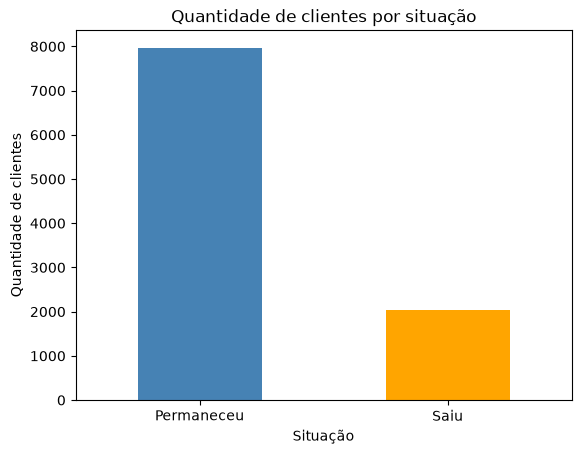

In [16]:
contagem_saida = dados["situacao"].value_counts()
contagem_saida.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Quantidade de clientes por situação")
plt.xlabel("Situação")
plt.ylabel("Quantidade de clientes")
plt.xticks(rotation=0)
plt.show()

**Leitura do gráfico:** o gráfico compara a quantidade de clientes que permaneceram com a quantidade dos que saíram. A porcentagem calculada acima permite medir melhor essa diferença.

### Pergunta 2 - A saída muda entre os países?

In [17]:
saida_pais = (
    dados.groupby("Geography")["Exited"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)
saida_pais

Geography
Germany    32.44
Spain      16.67
France     16.15
Name: Exited, dtype: float64

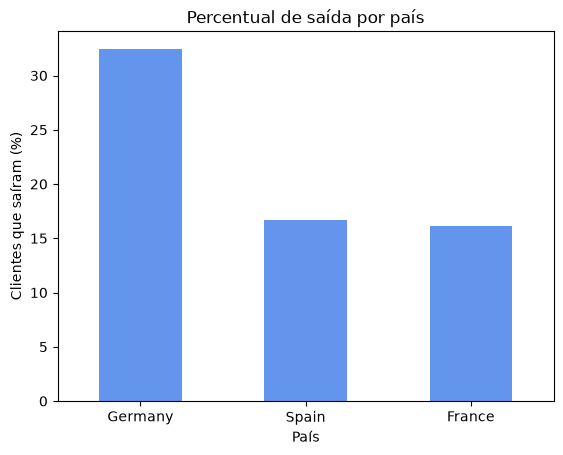

In [18]:
saida_pais.plot(kind="bar", color="cornflowerblue")
plt.title("Percentual de saída por país")
plt.xlabel("País")
plt.ylabel("Clientes que saíram (%)")
plt.xticks(rotation=0)
plt.show()

**Leitura do gráfico:** as barras mostram a proporção de saída em cada país. Como foi usada porcentagem, a comparação não depende apenas da quantidade de clientes de cada local.

### Pergunta 3 - Clientes ativos e inativos apresentam a mesma saída?

In [19]:
tabela_atividade = pd.crosstab(
    dados["atividade"],
    dados["situacao"],
    normalize="index"
).mul(100).round(2)

tabela_atividade

situacao,Permaneceu,Saiu
atividade,,
Ativo,85.73,14.27
Inativo,73.15,26.85


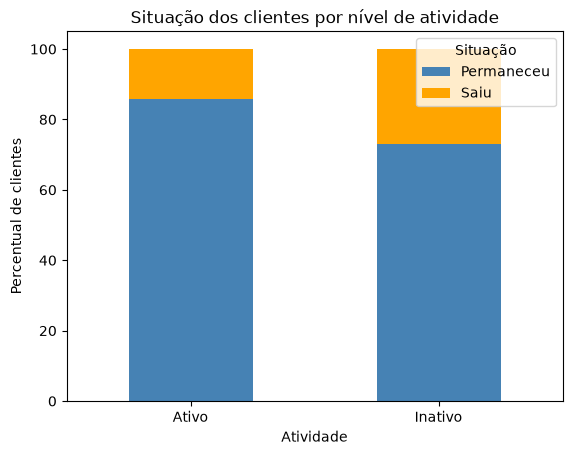

In [20]:
tabela_atividade.plot(kind="bar", stacked=True, color=["steelblue", "orange"])
plt.title("Situação dos clientes por nível de atividade")
plt.xlabel("Atividade")
plt.ylabel("Percentual de clientes")
plt.xticks(rotation=0)
plt.legend(title="Situação")
plt.show()

**Leitura do gráfico:** cada barra representa 100% do grupo. Assim, é possível comparar a parcela de saída entre clientes ativos e inativos.

### Pergunta 4 - A idade média é diferente entre os grupos?

In [21]:
idade_situacao = dados.groupby("situacao")["Age"].agg(["mean", "median", "count"]).round(2)
idade_situacao

,mean,median,count
situacao,,,
Permaneceu,37.41,36.0,7963
Saiu,44.84,45.0,2037


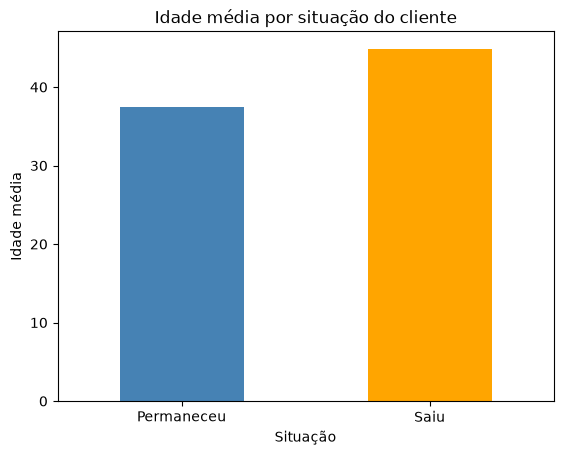

In [22]:
idade_situacao["mean"].plot(kind="bar", color=["steelblue", "orange"])
plt.title("Idade média por situação do cliente")
plt.xlabel("Situação")
plt.ylabel("Idade média")
plt.xticks(rotation=0)
plt.show()

**Leitura do gráfico:** o gráfico compara a idade média dos clientes que permaneceram e dos clientes que saíram. A mediana da tabela ajuda a verificar se a média está sendo puxada por idades mais extremas.

### Tabela-resumo

Para reunir os resultados principais, vou criar uma tabela por país e juntar a quantidade de clientes, a idade média e o percentual de saída.

In [23]:
resumo_pais = (
    dados.groupby("Geography")
    .agg(
        clientes=("Exited", "count"),
        idade_media=("Age", "mean"),
        percentual_saida=("Exited", "mean")
    )
    .reset_index()
)

resumo_pais["idade_media"] = resumo_pais["idade_media"].round(2)
resumo_pais["percentual_saida"] = (resumo_pais["percentual_saida"] * 100).round(2)
resumo_pais

,Geography,clientes,idade_media,percentual_saida
0,France,5014,38.51,16.15
1,Germany,2509,39.77,32.44
2,Spain,2477,38.89,16.67


## 6. Conclusões

As frases abaixo são geradas a partir dos números calculados no notebook. Isso evita escrever uma conclusão que não corresponda ao resultado da base utilizada.

In [24]:
pais_maior_saida = saida_pais.index[0]
maior_saida = saida_pais.iloc[0]

saida_atividade = dados.groupby("atividade")["Exited"].mean().mul(100)
grupo_maior_saida = saida_atividade.idxmax()
valor_grupo = saida_atividade.max()

media_saiu = dados.loc[dados["Exited"] == 1, "Age"].mean()
media_ficou = dados.loc[dados["Exited"] == 0, "Age"].mean()

print(f"1. Na base analisada, {taxa_geral:.2f}% dos clientes saíram do banco.")
print(f"2. O país com maior percentual de saída foi {pais_maior_saida}, com {maior_saida:.2f}%.")
print(f"3. O grupo {grupo_maior_saida.lower()} apresentou o maior percentual de saída, com {valor_grupo:.2f}%.")
print(f"4. A idade média de quem saiu foi {media_saiu:.1f} anos, contra {media_ficou:.1f} anos entre quem permaneceu.")

1. Na base analisada, 20.37% dos clientes saíram do banco.
2. O país com maior percentual de saída foi Germany, com 32.44%.
3. O grupo inativo apresentou o maior percentual de saída, com 26.85%.
4. A idade média de quem saiu foi 44.8 anos, contra 37.4 anos entre quem permaneceu.


### Limitações

A base não informa os motivos declarados pelos clientes para sair. Por isso, não é possível afirmar que idade, país ou atividade causaram o cancelamento. Também não há uma data detalhada para acompanhar mudanças ao longo do tempo.

### Próximos passos

Com mais tempo, seria interessante analisar o saldo, a quantidade de produtos e a pontuação de crédito em conjunto. Outra possibilidade seria obter dados de reclamações ou atendimento para entender melhor os motivos de saída.